# Huginn run: preliminary analysis

`runs/huginn_sampled_k1_p113_h3_x6` is the first looped model to grok multi-hop addition. Its recipe:
- a prelude block embeds the prompt into e;
- the loop starts from **random noise** s₀;
- each pass applies one shared core block to **concat-then-project(s, e)**, inside an **RMSNorm sandwich**;
- a coda block and a final norm read the answer out;
- the number of passes is **sampled each step** (log-normal Poisson, mean 8, capped at 24), with gradients through the **last 4 passes** only.

This notebook is preliminary; rerun it to follow the run. Because Huginn's validation accuracy collapses and recovers repeatedly, it scores every saved checkpoint (including `latest.pt`, which training overwrites every 1000 steps) and by default analyses the one with the best validation accuracy. It looks at:
1. **Training dynamics:** when it generalized, and the collapses afterwards.
2. **Fixed point:** accuracy and state change over passes 1 … T_MAX.
3. **Path independence:** whether different random starts end in the same state.
4. **Attention:** in the prelude and in the loop, as a function of hop count. Is it the NoPE anchor's even averaging again?
5. **The clock:** whether the logits are a clock of the total at every hop, and whether its amplitude dilutes like the NoPE anchor's.
6. **The embedding,** compared with the NoPE anchor.

In [1]:
# setup: run from the repo root so paths resolve, and import the code in src/
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import torch as t
import matplotlib.pyplot as plt

import analysis
import mech
import plot_progress as pp
import progress

%matplotlib inline
t.set_grad_enabled(False)
print("torch", t.__version__, "| cuda:", t.cuda.is_available())

/home/saafetensors/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/claude-1000/matplotlib-3yfmf5vd because there was an issue with the default path (/home/saafetensors/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


torch 2.14.1+cu130 | cuda: False


In [2]:
MUTED = "#c8c7c2"


def panel(ax, title, xlabel, ylabel, log_y=False):
    """style one axis the same way as the run figures.

    args:
        ax: matplotlib axis.
        title: panel title.
        xlabel: x-axis label.
        ylabel: y-axis label.
        log_y: use a log y scale.
    """
    pp.style_axis(ax, title, ylabel, log_y=log_y)
    ax.set_xlabel(xlabel, fontsize=9, color=pp.INK_2)


def freq_bars(ax, norms, highlight, title, ylabel="norm"):
    """bar chart of per-frequency norms, highlighting chosen frequencies and labelling the largest.

    args:
        ax: matplotlib axis.
        norms: tensor of shape (p//2 + 1,) from mech.freq_norms (index 0 is the constant).
        highlight: frequencies drawn in the accent colour.
        title: panel title.
        ylabel: y-axis label.
    """
    f = np.arange(1, len(norms))
    v = norms[1:].cpu().numpy()
    ax.bar(f, v, color=[pp.SERIES[0] if x in highlight else MUTED for x in f], width=0.8)
    for x in np.argsort(-v)[:5]:
        ax.annotate(str(f[x]), (f[x], v[x]), xytext=(0, 2), textcoords="offset points",
                    ha="center", fontsize=7, color=pp.INK_2)
    panel(ax, title, "frequency", ylabel)


def new_fig(n_rows, n_cols, width=12.5, height=3.8):
    """make a figure on the shared surface colour.

    args:
        n_rows: rows of panels.
        n_cols: columns of panels.
        width: figure width in inches.
        height: height per row in inches.
    returns:
        (figure, flat list of axes).
    """
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(width, height * n_rows), facecolor=pp.SURFACE, squeeze=False)
    return fig, list(axes.flat)

## Parameters

In [3]:
RUN_DIR = "runs/huginn_sampled_k1_p113_h3_x6"
CHECKPOINT = "best"  # "best", "latest.pt", or a file in checkpoints/
COMPARE_RUN = "runs/anchor_nope_p113_h3_x6"
T_MAX = 32
N_STARTS = 8
MAX_ROWS_PER_HOP = 1000
DEVICE = "cpu" 

In [4]:
import train

run = analysis.load_run(RUN_DIR, device=DEVICE)
p, T = run["cfg"].p, run["T"]
latest = run["run_dir"] / "latest.pt"
candidates = analysis.checkpoints(run) + [(t.load(latest, map_location="cpu", weights_only=False)["step"], latest)]
print("mean val accuracy (hops 1-3, at T) of every saved checkpoint:")
scores = {}
for s, pth in candidates:
    m = analysis.load_model(run, pth, DEVICE)
    res = train.evaluate(m, run["data"]["sets"]["val"], T, run["chunk_size"], analysis.eval_generator(run, DEVICE))
    scores[pth] = (s, np.mean([v["acc"] for v in res.values()]))
    print(f"  step {s:>6} ({pth.name}): {scores[pth][1]:.3f}")
if CHECKPOINT == "best":
    path = max(scores, key=lambda k: scores[k][1])
else:
    path = latest if CHECKPOINT == "latest.pt" else run["run_dir"] / "checkpoints" / CHECKPOINT
step = scores[path][0]
model = analysis.load_model(run, path, DEVICE)
basis = progress.fourier_basis(p)
print(f"checkpoint {CHECKPOINT} (step {step}); eval depth T = {T}")
print(run["cfg"])
print("depth rule:", run["entry"]["depth"])
by_part = {}
for name, prm in model.named_parameters():
    by_part[name.split(".")[0]] = by_part.get(name.split(".")[0], 0) + prm.numel()
print("parameters:", by_part, "| total", sum(by_part.values()))

sets = run["data"]["sets"]
by_hop = {**sets["val"], **sets["extrap_depth"]}
by_hop = {int(h): (x[:MAX_ROWS_PER_HOP], y[:MAX_ROWS_PER_HOP]) for h, (x, y) in by_hop.items()}
hops = sorted(by_hop)
gen = lambda seed=0: t.Generator().manual_seed(run["seed"] + 1 + seed)  # noqa: E731

mean val accuracy (hops 1-3, at T) of every saved checkpoint:


  step    100 (step_0000100.pt): 0.021


  step    128 (step_0000128.pt): 0.035


  step    165 (step_0000165.pt): 0.041


  step    211 (step_0000211.pt): 0.036


...

  step   3295 (step_0003295.pt): 0.049


  step   4229 (step_0004229.pt): 0.109


  step   5429 (step_0005429.pt): 0.539


  step   6968 (step_0006968.pt): 0.995


  step   8000 (latest.pt): 0.387
checkpoint best (step 6968); eval depth T = 8
ModelConfig(p=113, pos='none', n_ctx=0, norm='rms_sandwich', n_prelude=1, k=1, core_shared=True, n_core_copies=1, injection='concat', state_init='random', n_coda=1, state_norm=False, d_model=128, num_heads=4, d_head=32, d_mlp=512)
depth rule: {'rule': 'sampled', 'mean': 8, 'sigma': 0.5, 'cap': 24, 'grad_iters': 4}
parameters: {'W_A': 32768, 'embed': 14592, 'prelude': 197760, 'core': 197760, 'core_norm': 128, 'coda': 197760, 'coda_norm': 128, 'unembed': 14464} | total 655360


## 1. Training dynamics

Logged every 100 steps. The *step loss* is measured at that step's sampled depth with a fresh random start, so part of its noise is measurement. The *train loss at fixed T* is measured at T = 8 with a fixed generator, so its swings are real changes in the model. Below: when validation accuracy first passed 0.9, and every collapse after that (mean val accuracy over hops 1–3 below 0.5).

val accuracy first above 0.9 at step 4700
collapse at step 5300 (below 0.5 until 5300, lowest mean val acc 0.079)
collapse at step 6800 (below 0.5 until 7100, lowest mean val acc 0.049)
collapse at step 8000 (below 0.5 until 8100, lowest mean val acc 0.088)


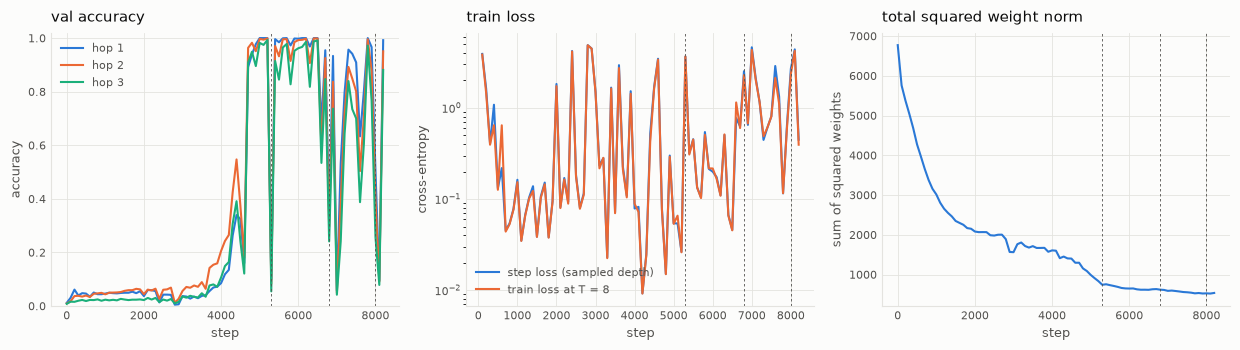

In [5]:
logged = pp.load_evals(run["run_dir"])
steps = [r["step"] for r in logged]
val_mean = [np.mean([v["acc"] for v in r["val"].values()]) for r in logged]
grok = next((s for s, v in zip(steps, val_mean) if v > 0.9), None)
print("val accuracy first above 0.9 at step", grok)
collapses, inside = [], False
for s, v in zip(steps, val_mean):
    if grok and s > grok and v < 0.5 and not inside:
        collapses.append([s, s, v]); inside = True
    elif inside and v < 0.5:
        collapses[-1][1:] = [s, min(collapses[-1][2], v)]
    elif inside and v > 0.9:
        inside = False
for start, end, low in collapses:
    print(f"collapse at step {start} (below 0.5 until {end}, lowest mean val acc {low:.3f})")

fig, axes = new_fig(1, 3, height=3.6)
hop_keys = sorted(logged[-1]["val"], key=int)
pp.draw_lines(axes[0], steps, [(f"hop {h}", [r["val"][h]["acc"] for r in logged]) for h in hop_keys], ylim=(0, 1.02), end_labels=False)
panel(axes[0], "val accuracy", "step", "accuracy")
fixed = [np.mean([v["loss"] for v in r["train"].values()]) for r in logged]
pp.draw_lines(axes[1], steps[1:], [("step loss (sampled depth)", [r["train_step_loss"] for r in logged[1:]]),
                                     ("train loss at T = 8", fixed[1:])], end_labels=False)
panel(axes[1], "train loss", "step", "cross-entropy", log_y=True)
pp.draw_lines(axes[2], steps, [("weights", [r["progress"]["sum_sq_weights"] for r in logged])], end_labels=False, legend=False)
panel(axes[2], "total squared weight norm", "step", "sum of squared weights")
for ax in axes:
    for start, _, _ in collapses:
        ax.axvline(start, color=pp.INK_2, linewidth=0.6, linestyle=(0, (3, 3)))
plt.tight_layout(); plt.show()

## 2. Fixed point

Accuracy when reading out after every pass 1 … T_MAX (a 2-pass solution would saturate at pass 2), and how much the state at `=` still changes per pass: ‖s_t − s_{t−1}‖ / ‖s_t‖, median over prompts.

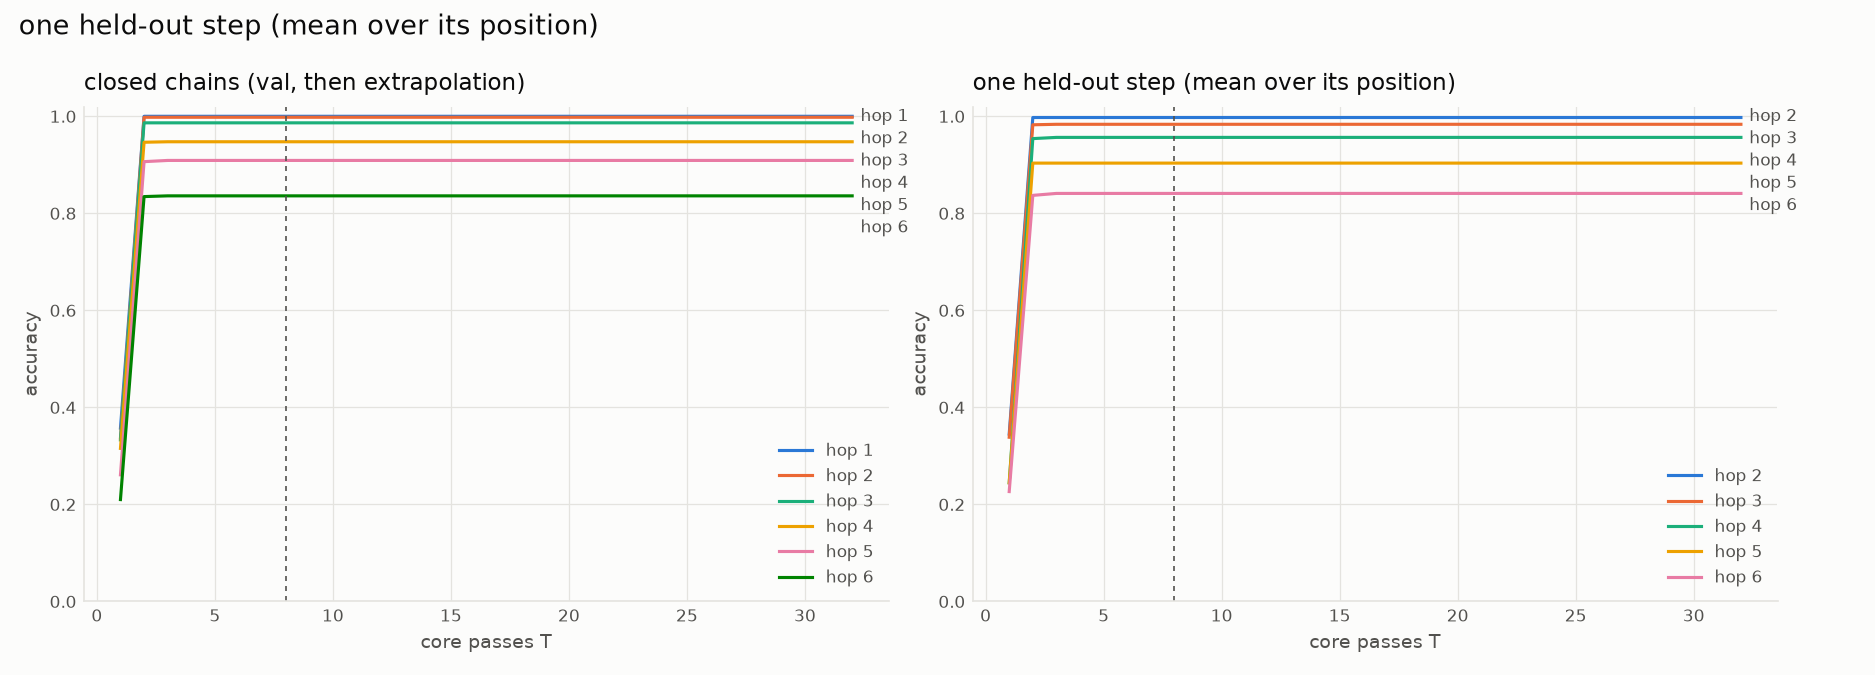

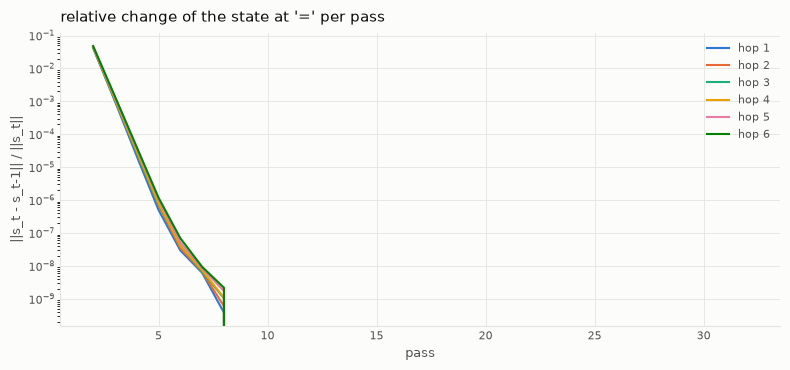

hop 1: relative change at passes 2, 4, 8, 32: 4.2e-02, 2.2e-05, 3.8e-10, 0.0e+00
hop 2: relative change at passes 2, 4, 8, 32: 4.3e-02, 2.8e-05, 6.0e-10, 0.0e+00
hop 3: relative change at passes 2, 4, 8, 32: 4.4e-02, 2.9e-05, 1.0e-09, 0.0e+00
hop 4: relative change at passes 2, 4, 8, 32: 4.5e-02, 3.1e-05, 1.1e-09, 0.0e+00
hop 5: relative change at passes 2, 4, 8, 32: 4.6e-02, 3.8e-05, 1.7e-09, 0.0e+00
hop 6: relative change at passes 2, 4, 8, 32: 4.8e-02, 4.1e-05, 2.2e-09, 0.0e+00


In [6]:
by_T = analysis.depth_sweep(run, path, T_MAX, DEVICE)
display_title = f"{run['name']}: accuracy by depth at step {step}"
from IPython.display import Image, display
display(Image(filename=str(pp.plot_sweep(by_T, display_title, run["run_dir"] / "analysis" / "huginn_depth_sweep.png", train_T=T))))

change = {}
for hop in hops:
    x, y = by_hop[hop]
    _, cache = mech.run_cache(model, x, T_MAX, generator=gen())
    s = t.stack([cache[("hook_state", i)][:, -1] for i in range(T_MAX)])  # (T_MAX, rows, d)
    rel = (s[1:] - s[:-1]).norm(dim=-1) / s[1:].norm(dim=-1)
    change[hop] = rel.median(dim=1).values.tolist()
fig, axes = new_fig(1, 1, width=8)
pp.draw_lines(axes[0], list(range(2, T_MAX + 1)), [(f"hop {h}", change[h]) for h in hops], end_labels=False)
panel(axes[0], "relative change of the state at '=' per pass", "pass", "||s_t - s_t-1|| / ||s_t||", log_y=True)
plt.tight_layout(); plt.show()
for h in hops:
    print(f"hop {h}: relative change at passes 2, 4, 8, {T_MAX}: " + ", ".join(f"{change[h][i - 2]:.1e}" for i in (2, 4, 8, T_MAX)))

## 3. Path independence

Run the same prompts from N_STARTS different random starts. If the loop has one attracting fixed point per prompt, then by the training depth the states from different starts should coincide and the predictions agree. Shown: the spread of the final state across starts relative to its norm, and how often every start gives the same answer.

In [7]:
print(f"{'hop':>3} {'pass':>5} {'state spread / norm':>20} {'all starts agree':>17} {'acc (mean over starts)':>23}")
for hop in hops:
    x, y = by_hop[hop]
    for n_iter in (1, 2, T, T_MAX):
        states, preds = [], []
        for k in range(N_STARTS):
            _, cache = mech.run_cache(model, x, n_iter, generator=gen(k))
            states.append(cache[("hook_state", n_iter - 1)][:, -1])
            preds.append(model(x, n_iter, generator=gen(k)).argmax(-1))
        S = t.stack(states)
        spread = (S - S.mean(0)).norm(dim=-1).mean(0) / S.mean(0).norm(dim=-1)
        P = t.stack(preds)
        agree = (P == P[0]).all(0).float().mean().item()
        acc = (P == y).float().mean().item()
        print(f"{hop:>3} {n_iter:>5} {spread.median().item():>20.2e} {agree:>17.3f} {acc:>23.3f}")

hop  pass  state spread / norm  all starts agree  acc (mean over starts)


  1     1             4.02e-02             0.001                   0.371


  1     2             1.01e-03             1.000                   1.000


  1     8             6.75e-08             1.000                   1.000


  1    32             6.75e-08             1.000                   1.000


...

  5    32             6.69e-08             1.000                   0.911


  6     1             4.44e-02             0.001                   0.216


  6     2             1.39e-03             0.947                   0.822


  6     8             6.67e-08             1.000                   0.825


  6    32             6.67e-08             1.000                   0.825


## 4. Attention

Huginn has attention in the prelude (once) and in the core (every pass). For each, the weight from `=` onto `=` itself and the mean weight per operand, as a function of hop count, compared with even averaging 1/(h + 2). With injection, the core's query at `=` depends on the state, so unlike the NoPE anchor the scores aren't a fixed function of token value; they come from the hooks.

In [8]:
names = sorted({n for n, _ in mech.run_cache(model, by_hop[1][0][:4], 2)[1] if n.endswith("attn.hook_attn")})
print("attention hooks:", names)
rows = []
shown = {}
for hop in hops:
    x, y = by_hop[hop]
    _, cache = mech.run_cache(model, x, T, generator=gen())
    for name in names:
        # the prelude runs once, the core every pass (first, second and last shown), the coda once at readout
        its = sorted((it for n, it in cache if n == name), key=lambda i: -1 if i is None else i)
        shown[name] = its if name.startswith(("prelude", "coda")) else [its[0], its[1], its[-1]]
        for it in shown[name]:
            a = cache[(name, it)][:, :, -1]  # (rows, heads, positions)
            rows.append((name, it, hop, a[:, :, -1].mean(0).tolist(), a[:, :, :-1].mean((0, 2)).tolist(),
                         (mech.entropy(a).mean(0) / np.log(hop + 2)).tolist()))
for name in ["prelude.0.attn.hook_attn", "core.0.0.attn.hook_attn", "coda.0.attn.hook_attn"]:
    for it in shown[name]:
        label = name.replace(".attn.hook_attn", "") + (f", pass {it + 1}" if name.startswith("core") else "")
        print(f"\n{label}")
        for _, _, hop, eq, op, ent in [r for r in rows if r[0] == name and r[1] == it]:
            print(f"  hop {hop}: on '=' {[round(v, 2) for v in eq]}, per operand {[round(v, 3) for v in op]} "
                  f"(even: {1 / (hop + 2):.3f}), entropy/max {[round(v, 2) for v in ent]}")

attention hooks: ['coda.0.attn.hook_attn', 'core.0.0.attn.hook_attn', 'prelude.0.attn.hook_attn']



prelude.0
  hop 1: on '=' [0.33, 0.33, 0.33, 0.33], per operand [0.333, 0.333, 0.333, 0.333] (even: 0.333), entropy/max [1.0, 1.0, 1.0, 1.0]
  hop 2: on '=' [0.25, 0.25, 0.25, 0.25], per operand [0.25, 0.25, 0.25, 0.25] (even: 0.250), entropy/max [1.0, 1.0, 1.0, 1.0]
  hop 3: on '=' [0.2, 0.2, 0.2, 0.2], per operand [0.2, 0.2, 0.2, 0.2] (even: 0.200), entropy/max [1.0, 1.0, 1.0, 1.0]
  hop 4: on '=' [0.17, 0.17, 0.17, 0.17], per operand [0.167, 0.167, 0.167, 0.167] (even: 0.167), entropy/max [1.0, 1.0, 1.0, 1.0]
  hop 5: on '=' [0.14, 0.14, 0.14, 0.14], per operand [0.143, 0.143, 0.143, 0.143] (even: 0.143), entropy/max [1.0, 1.0, 1.0, 1.0]
  hop 6: on '=' [0.13, 0.13, 0.13, 0.13], per operand [0.125, 0.125, 0.125, 0.125] (even: 0.125), entropy/max [1.0, 1.0, 1.0, 1.0]

core.0.0, pass 1
  hop 1: on '=' [0.33, 0.33, 0.33, 0.33], per operand [0.333, 0.333, 0.333, 0.333] (even: 0.333), entropy/max [1.0, 1.0, 1.0, 1.0]
  hop 2: on '=' [0.25, 0.25, 0.25, 0.25], per operand [0.25, 0.25, 0.2

## 5. The clock

At the training depth, fit logit(c) by cos/sin(w(Σx − c)) at Huginn's key frequencies, per hop count, and compare the clock amplitude × (h + 2) with the NoPE anchor's. A constant product means the answer signal dilutes like an even average over the h + 2 tokens.

In [9]:
measures = progress.progress_measures(model, *run["data"]["grid"], T, generator=gen())
KEYS = measures["key_freqs"]
print("key frequencies:", KEYS, "| logit norms:", [round(measures["logit_freq_norms"][f - 1], 1) for f in KEYS])
print(f"restricted loss {measures['restricted_loss']:.3f}, excluded loss {measures['excluded_loss']:.3f}, "
      f"grid test acc {measures['grid_test_acc']:.3f}")

ref = analysis.load_run(COMPARE_RUN, device=DEVICE)
ref_model = analysis.load_model(ref, ref["run_dir"] / "checkpoints" / "final.pt", DEVICE)
ref_keys = progress.progress_measures(ref_model, *ref["data"]["grid"], 1)["key_freqs"]
print(f"\n{'':>3} {'huginn':^42} {'nope anchor':^42}")
print(f"{'hop':>3} " + f"{'acc':>7} {'clock R^2':>10} {'amp':>7} {'amp x (h+2)':>12}   " * 2)
for hop in hops:
    x, y = by_hop[hop]
    out = []
    for m, keys, n_iter in [(model, KEYS, T), (ref_model, ref_keys, 1)]:
        logits = m(x, n_iter, generator=gen())
        fitted, r2 = mech.clock_fit(logits, y, keys, p)
        amp = fitted.std(-1).mean().item()
        out.append(f"{mech.loss_and_acc(logits, y)[1]:>7.3f} {r2:>10.3f} {amp:>7.2f} {amp * (hop + 2):>12.1f}")
    print(f"{hop:>3} " + "   ".join(out))

key frequencies: [12, 31, 16, 18, 10] | logit norms: [1525.9, 1198.5, 932.2, 798.0, 685.4]
restricted loss 0.934, excluded loss 1.012, grid test acc 1.000



                      huginn                                  nope anchor                
hop     acc  clock R^2     amp  amp x (h+2)       acc  clock R^2     amp  amp x (h+2)   
  1   1.000      0.689    1.93          5.8     0.998      0.880   13.32         40.0
  2   0.997      0.674    1.91          7.6     0.998      0.883   10.20         40.8


  3   0.989      0.646    1.87          9.4     0.982      0.859    8.01         40.1
  4   0.944      0.588    1.78         10.7     0.943      0.802    6.55         39.3


  5   0.911      0.517    1.68         11.7     0.878      0.662    5.35         37.5
  6   0.825      0.429    1.53         12.2     0.842      0.581    4.56         36.5


## 6. The embedding

W_E by frequency for Huginn and the NoPE anchor, each with its own key frequencies highlighted. Huginn's prelude can reshape the embedding before the loop, so W_E alone may matter less here.

huginn_sampled_k1_p113_h3_x6: W_E gini 0.195; top frequencies [41, 6, 8, 31, 16, 10, 47, 25]
anchor_nope_p113_h3_x6: W_E gini 0.234; top frequencies [32, 50, 10, 16, 4, 14, 26, 20]


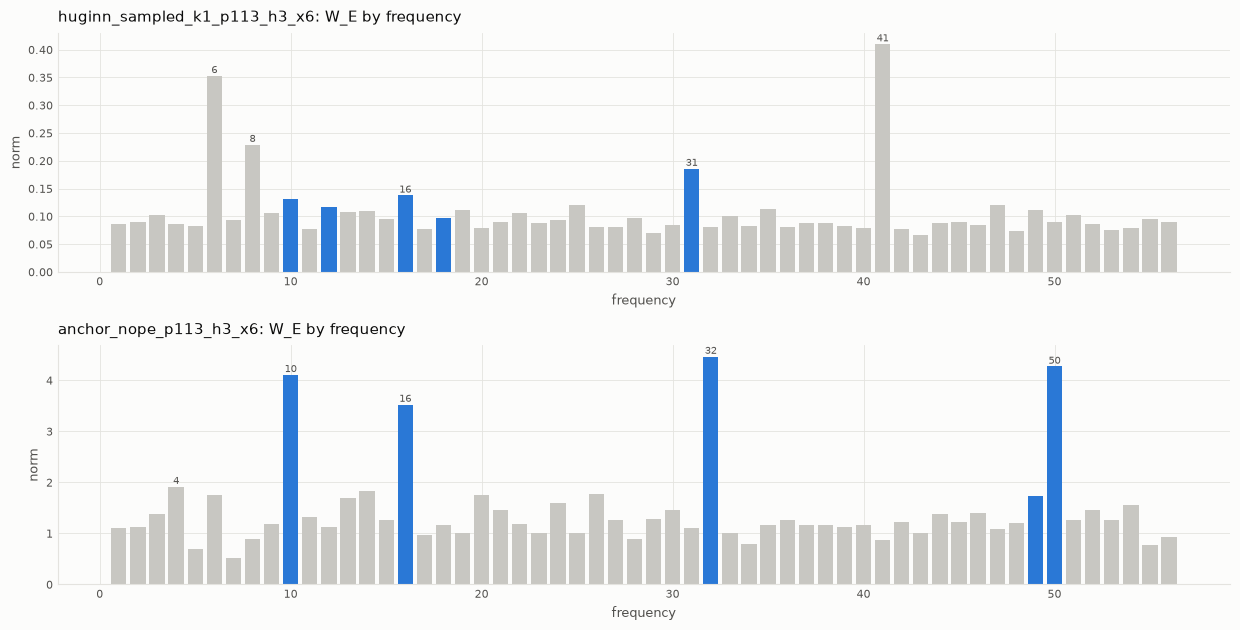

In [10]:
fig, axes = new_fig(2, 1, height=3.2)
for ax, (name, m, keys) in zip(axes, [(run["name"], model, KEYS), (ref["name"], ref_model, ref_keys)]):
    norms = mech.freq_norms(m.embed.W_E[:, :p], basis)
    freq_bars(ax, norms, keys, f"{name}: W_E by frequency")
    print(f"{name}: W_E gini {progress.gini(norms[1:]):.3f}; top frequencies {(norms[1:].argsort(descending=True)[:8] + 1).tolist()}")
plt.tight_layout(); plt.show()

## Reading (preliminary)

Numbers below are for the best checkpoint so far (step 6968, mean val accuracy 0.995). The run was still training when this was written.

**Instability.**
- Val accuracy first passed 0.9 at step 4.7k, then collapsed at 5.3k, 6.8k–7.1k and 8.0k.
- `latest.pt` at 8000 scores 0.39.
- A collapsed model (step 7000, looked at separately) is still a perfect, path-independent fixed point; it just converges to wrong answers. Collapses break what the map computes, not whether it converges.

**A fast fixed point that ignores where it starts.**
- The state at `=` changes by 4e-2 (relative) at pass 2, 2e-5 at pass 4 and 4e-10 at pass 8.
- After one pass, different random starts still disagree: they almost never all agree, and hop-1 accuracy is 0.37. By pass 2 they agree on ≥ 95% of prompts, and by pass 8 the states match to 7e-8.
- Accuracy at pass 2 already equals the final accuracy. The loop is a strongly contracting map that settles in about 2 passes; later passes do nothing.

**Attention is an exact average everywhere.**
- In the prelude, every core pass and the coda, every head puts weight 1/(h + 2) on each token (normalized entropy 1.00).
- Query and key weights shrank about 10× between steps 4.2k and 7.0k, as generalization appeared (core |W_Q| 15.3 → 1.6). The model dropped content-based attention and kept pure averaging, a stronger version of the NoPE anchor's near-even attention.

**The clock is weaker and doesn't dilute.**
- The logits are less clock-like than the NoPE anchor's: R² 0.69 against 0.88 at hop 1. On the hop-1 table, restricted loss is 0.93 and excluded loss 1.01 with key frequencies [12, 31, 16, 18, 10]. The answer is spread over more frequencies, and the key set is still shifting.
- Unlike the NoPE anchor, the clock's amplitude barely shrinks with chain length: 1.93 → 1.53 from hop 1 to 6, so amplitude × (h + 2) *rises* from 5.8 to 12.2. A plausible cause, not yet checked, is the RMSNorm after each attention rescaling the pooled average.
- Even so, extrapolation is about the same as the NoPE anchor's (0.94 / 0.91 / 0.83 against 0.94 / 0.88 / 0.84 on the same 1000 rows), while the clock R² falls with hop count. Huginn's long-chain errors don't come from dilution but from a less accurate decoding of the average.

**The embedding is dense** (gini 0.20), like the NoPE anchor's.

**Working picture.** Huginn averages all tokens (in the prelude and again in every pass), lets the MLPs turn that average into the answer, and settles to a fixed point in about 2 passes. On this task the loop buys stability (any start gives the same answer) rather than extra computation.